# Vision Transformer on handwritten digits

Cut each digit into sixteen patches and train a class token to classify the image. A confusion matrix shows which digits remain difficult at this resolution.

The images are the 8 × 8 optical digits bundled with scikit-learn. A learnable linear patch projection, positional embeddings, a class token and two self-attention blocks make a small Vision Transformer. The split is by image. Writer identities are unavailable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


def encoder(width=32):
    return nn.TransformerEncoderLayer(
        d_model=width, nhead=4, dim_feedforward=64, dropout=0, batch_first=True, activation="gelu"
    )


from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix


class DigitViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patches = nn.Conv2d(1, 48, kernel_size=2, stride=2)
        self.cls = nn.Parameter(torch.zeros(1, 1, 48))
        self.pos = nn.Parameter(torch.randn(1, 17, 48) * 0.18)
        self.blocks = nn.Sequential(encoder(48), encoder(48))
        self.head = nn.Linear(48, 10)

    def forward(self, x):
        tokens = self.patches(x).flatten(2).transpose(1, 2)
        z = torch.cat([self.cls.expand(len(x), -1, -1), tokens], 1) + self.pos
        return self.head(self.blocks(z)[:, 0])

## Train on the image split

Pixels are divided by their fixed maximum intensity of 16. Labels are used for supervised training and a stratified split.

In [2]:
seed()
digits = load_digits()
train, test = train_test_split(
    np.arange(len(digits.target)), test_size=0.25, random_state=17, stratify=digits.target
)
x = torch.tensor(digits.images[:, None], dtype=torch.float32) / 16
y = torch.tensor(digits.target, dtype=torch.long)
train = torch.tensor(train)
model = DigitViT()
opt = torch.optim.AdamW(model.parameters(), lr=0.0025, weight_decay=0.01)
curve = []
for epoch in range(24):
    total = 0.0
    for ids in train[torch.randperm(len(train))].split(64):
        loss = F.cross_entropy(model(x[ids]), y[ids])
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(ids)
    curve.append(total / len(train))

## Inspect test errors

One held-out pass supplies class predictions, a confusion matrix and log loss. The flat-probability reference assigns each digit probability 0.1.

,Test images,Accuracy,Balanced accuracy,Macro F1,Test NLL,Uniform NLL
0,450,0.98222,0.98196,0.98214,0.06071,2.30259


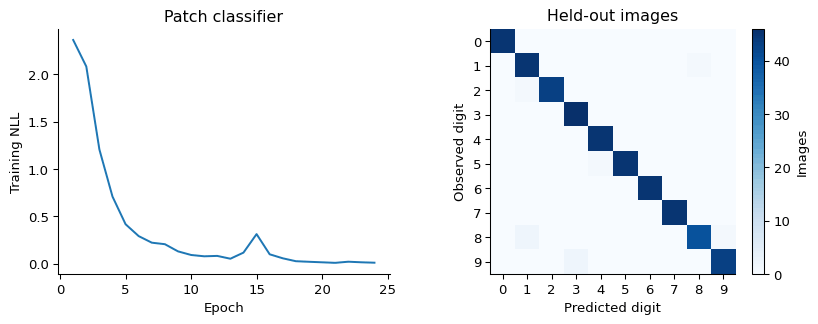

In [3]:
model.eval()
with torch.no_grad():
    logits = torch.cat([model(batch) for batch in x[test].split(64)])
    pred = logits.argmax(1).numpy()
truth = y[test].numpy()
counts = confusion_matrix(truth, pred, labels=np.arange(10))
report(
    ["Test images", "Accuracy", "Balanced accuracy", "Macro F1", "Test NLL", "Uniform NLL"],
    [
        (
            len(test),
            np.mean(pred == truth),
            balanced_accuracy_score(truth, pred),
            f1_score(truth, pred, average="macro"),
            F.cross_entropy(logits, y[test]).item(),
            np.log(10),
        )
    ],
)
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.3), layout="constrained")
axes[0].plot(range(1, len(curve) + 1), curve)
axes[0].set(xlabel="Epoch", ylabel="Training NLL", title="Patch classifier")
im = axes[1].imshow(counts, cmap="Blues")
axes[1].set(
    xticks=range(10),
    yticks=range(10),
    xlabel="Predicted digit",
    ylabel="Observed digit",
    title="Held-out images",
)
fig.colorbar(im, ax=axes[1], label="Images")
plt.show()

## Interpreting the result

The model classified 442 of 450 held-out images correctly. Balanced accuracy was 0.982 and macro F1 was 0.982. Those scores concern an image-level split of the small optical digit images.

Errors away from the diagonal identify pairs worth inspecting in the original images. These scores describe small images and a single image-level split.

## Exercise

Replace the class token readout with a mean over encoded patches. Keep the split and optimiser settings fixed.

## References

[Dosovitskiy et al. (2021), An Image is Worth 16x16 Words](https://arxiv.org/abs/2010.11929)

[Alpaydin and Kaynak (1998), Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)